# Train MATwin: polynomial performance function (Fresno, 25 km²)
Saved outputs are from the run reported in Table 3 of the paper; input data are not included (see the README). Map tiles © OpenStreetMap contributors.

## Setup


In [1]:
import sys
import os
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import ast
import numpy as np
import pandas as pd
import geopandas as gpd
import contextily as ctx
import random
import glob
import time
from sklearn import preprocessing
from sklearn.impute import SimpleImputer
import osmnx as nx
from shapely.geometry import LineString

import tensorflow as tf

tf.config.set_visible_devices([], "GPU")

2026-02-13 04:58:53.037620: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-13 04:58:53.073386: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-02-13 04:58:54.031379: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


2026-02-13 04:58:55.875130: W tensorflow/core/common_runtime/gpu/gpu_device.cc:1960] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [2]:
#!pip install shapely==1.8.5


In [3]:
# Path management
main_dir = str(Path(os.path.abspath("")).parents[0])
os.chdir(main_dir)
print("main dir:", main_dir)

sys.path.append(os.path.join(main_dir, "src"))

# Folder that contains information of reference O-D matrix/pairs and paths.
import isuelogit as isl

# isl.config.dirs['read_network_data'] = "input/network-data/fresno/"
isl.config.dirs["read_network_data"] = "data/input"

main dir: .


In [4]:
# User need to provide the area of intrest and exisiting timestamp. Or else run the 01_build_network.ipynb
area_of_interest = 'Fresno'
ts_data = '250327231442'
_YEAR=2024

In [5]:
folder_path = os.path.join(main_dir, 'data', area_of_interest, ts_data)

print(folder_path)
if not os.path.exists(folder_path):
    print("Path does not exists!! Check the folder path")

./data/Fresno/250327231442


In [6]:
%load_ext autoreload
%autoreload 2

from pesuelogit.networks import read_OD
from pesuelogit.etl import add_period_id

# Functions from internal modules
from mate.models import compute_generation_factors, create_tvodlulpe_model, create_mattwin_model, compute_benchmark_metrics
from mate.etl import build_network, get_tensors_by_year, data_curation
from mate.visualizations import  plot_predictive_performance, plot_top_od_flows_periods, \
    plot_utility_parameters_periods, plot_rr_by_period, plot_rr_by_period_models, plot_total_trips_models, \
    plot_performance_functions, plot_flow_vs_traveltime, plot_flow_interaction_matrix, \
    plot_convergence_estimates, plot_parameters, plot_relative_gap_by_period, plot_congestion_maps, \
    plot_equilibrium_loss_by_period
from mate.metrics import mse, mape, mdape, r2_score, z2score
from mate.utils import read_paths, load_k_shortest_paths, flat_od_from_generated_trips

main dir: .


### Hyperparameters and configurations


In [7]:
# Data

_DAYSOFWEEK = [1, 2, 3]  # Monday:0, Sunday:6
# _HOURS = np.arange(16,17)
_HOURS = list(range(0, 24))

# Loss function
_LOSS_WEIGHTS = {
    #"TVODLULPE": {"od": 0, "traveltime": 1, "flow": 1, "equilibrium": 1},
    "MaTE": {"od": 0, "traveltime": 1, "flow": 1, "equilibrium": 1}, 
    
}
_LOSS_METRIC = z2score

# Optimization
_BATCH_SIZE = 1  # 1
# _LR = {'TVODLULPE': {'learning': 5e-2},
#        'MaTE': {'learning': 5e-2, 'generation': 10}}
_LR = {
       #"TVODLULPE": {"learning": 1e-1}, 
       "MaTE": {"learning": 1e-1, "generation": 1e1}} #increase to 5e-1 for training error improvement
       #"MaTE": {"learning": 5e-1, "generation": 1e1}}
_EPOCHS = {
    #"TVODLULPE": {"learning": 20, "equilibrium": 0},
    "MaTE": {"learning": 40, "equilibrium": 0},
    #"MaTE": {"learning": 2, "equilibrium": 0},
}
_OPTIMIZERS = {
    model: {key: tf.keras.optimizers.legacy.Adam(learning_rate=lr) for key, lr in lrs.items()}
    for model, lrs in _LR.items()
}

# Evaluation metric reported during model training
# _EVALUATION_METRIC = mdape
_EVALUATION_METRIC = mape

# Equilibrium condition (if different than 'inf', equilibrium 'epochs' must be greater than 0)
_RELATIVE_GAP = float("inf")

# Exogenous attributes in utility function
_FEATURES_Z = []

# Numeric type of tensors
_DTYPE = tf.float32

In [8]:
# Seed for reproducibility
_SEED = 2024
np.random.seed(_SEED)
random.seed(_SEED)
tf.random.set_seed(_SEED)

# To report global runtime
t0_global = time.time()

# Set timestamp to add in the filenames that are written in disk
ts = datetime.now().strftime("%y%m%d%H%M%S")
print("Timestamp:", ts)

Timestamp: 260213045856


In [9]:
network_crs = "EPSG:4326"

## Read node and link level data


In [10]:
os.getcwd()

'.'

In [11]:
# nodes_df = pd.read_csv('./input/network-data/fresno/nodes/fresno-nodes-gis-data.csv')
nodes_df = pd.read_csv(folder_path+"/output/node_specific_data.csv", sep="\t")

# links_df = pd.read_csv('./input/network-data/fresno/links/fresno-link-specific-data.csv',
# converters={"link_key": ast.literal_eval, "pems_id": ast.literal_eval})

links_df = pd.read_csv(folder_path+"/output/link_specific_data.csv",
    sep="\t",
    converters={"link_key": ast.literal_eval},  # , "pems_id": ast.literal_eval
)

In [12]:
links_df.head(3)

,link_key,link_keys_osmids,osmid_link,u,v,length,maxspeed,lanes,capacity,link_type,key_u,key_v,lon_u,lat_u,lon_v,lat_v,maxspeed_float,maxspeed_impute,tf_inrix
0,"(0, 1, 0)","(87341387, 87341389, '0')",10320396,87341387,87341389,131.69400,NaN,1.0,2000,street,0,1,-119.812982,36.733850,-119.811504,36.733874,NaN,39.483204,7.461193
1,"(0, 1986, 0)","(87341387, 12418848817, '0')",12418849746,87341387,12418848817,214.76614,inf,inf,999999,attractor,0,1986,-119.812982,36.733850,-119.815280,36.734420,NaN,39.483204,12.167689
2,"(1, 0, 0)","(87341389, 87341387, '0')",10320396,87341389,87341387,131.69400,NaN,1.0,2000,street,1,0,-119.811504,36.733874,-119.812982,36.733850,NaN,39.483204,7.461193


In [13]:
nodes_df.head(3)

,key,osmid,type,lon,lat
0,0,87341387,real,-119.812982,36.733850
1,1,87341389,real,-119.811504,36.733874
2,2,87341391,real,-119.810046,36.733875


In [14]:
links_df.shape, nodes_df.shape

((7245, 19), (2143, 5))

## Build network


In [15]:
links_df["link_key"].nunique()

7245

In [16]:
# network = build_network(links_df=links_df, nodes_df=nodes_df, crs='epsg:4326', key= 'fresno')
network = build_network(
    links_df=links_df,
    nodes_df=nodes_df,
    node_id_label="osmid",
    link_id_label="osmid_link",
    crs=network_crs,
    key=area_of_interest,
)

In [17]:
links = pd.read_csv(folder_path+"/output/link_specific_data.csv", sep="\t")
links["geometry"] = links.apply(
    lambda row: LineString([[row["lon_u"], row["lat_u"]], [row["lon_v"], row["lat_v"]]]),
    axis=1,
)

.../site-packages/pandas/core/dtypes/cast.py:130: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)


In [18]:
# Create geodataframe
gdf_links = gpd.GeoDataFrame(links, crs=network_crs)
# Create a shp file
link_shp_file = folder_path+f"/output/{area_of_interest}-links-gis.shp"
gdf_links[["link_key", "link_type", "geometry"]].to_file(link_shp_file, mode="w")

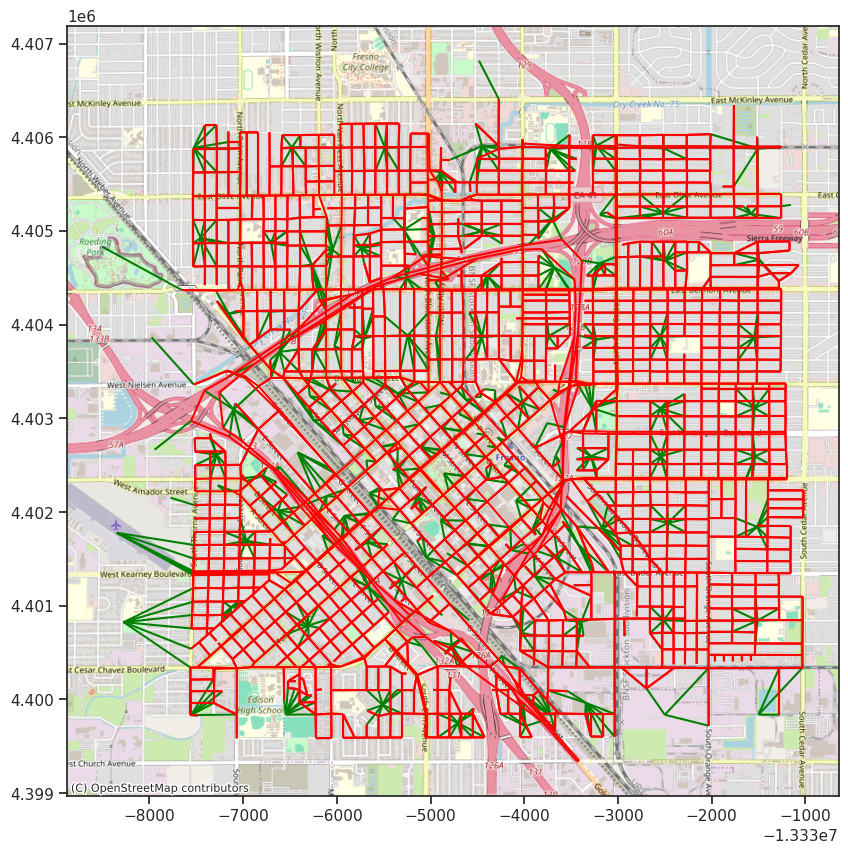

In [19]:
# Display network
fig, ax = plt.subplots(figsize=(10, 10))
links_gdf = gpd.read_file(folder_path+f"/output/{area_of_interest}-links-gis.shp").set_crs("EPSG:4326")
links_gdf[links_gdf["link_type"] == "attractor"].to_crs(epsg=3857).plot(ax=ax, color="g")
links_gdf[links_gdf["link_type"] == "street"].to_crs(epsg=3857).plot(ax=ax, color="r")
ctx.add_basemap(ax=ax, source=ctx.providers.OpenStreetMap.Mapnik)

In [20]:
# Links of type connector

links_gdf[links_gdf["link_type"] == "attractor"].shape

(975, 3)

In [21]:
links_gdf["link_type"].value_counts()

link_type
street       5295
attractor     975
generator     975
Name: count, dtype: int64

# Create Q' for virtual nodes


In [22]:
import scipy.sparse as sps

rows, cols = nodes_df.shape[0], nodes_df.shape[0]

In [23]:
# create an empty matrix
sps_acc = sps.coo_matrix((rows, cols))
sps_acc

<2143x2143 sparse matrix of type '<class 'numpy.float64'>'
	with 0 stored elements in COOrdinate format>

In [24]:
# Create sparse adjacency matrix for generators and attractors
# Robust method: Connect all Generators to all Attractors (excluding self-loops) using index lookup

generator_indices = nodes_df[nodes_df["type"] == "generator"].index.values
attractor_indices = nodes_df[nodes_df["type"] == "attractor"].index.values

# Restore legacy variable names for compatibility
index_generator = generator_indices
index_attractor = attractor_indices

print(f"Generators: {len(generator_indices)}, Attractors: {len(attractor_indices)}")

rows = []
cols = []
data = []

if len(generator_indices) > 0 and len(attractor_indices) > 0:
    # Use meshgrid to generate all pairs
    # Note: numpy meshgrid with indexing='ij' gives matrix indexing
    import numpy as np
    g_mesh, a_mesh = np.meshgrid(generator_indices, attractor_indices, indexing='ij')
    
    g_flat = g_mesh.flatten()
    a_flat = a_mesh.flatten()
    
    # Remove self-loops
    mask = (g_flat != a_flat)
    
    rows = g_flat[mask]
    cols = a_flat[mask]
    data = np.ones_like(rows)

# Create the coo_matrix directly
# Assuming scipy.sparse as sps is imported
sps_acc = sps.coo_matrix((data, (rows, cols)), shape=(nodes_df.shape[0], nodes_df.shape[0]))
sps_acc

Generators: 147, Attractors: 147


<2143x2143 sparse matrix of type '<class 'numpy.int64'>'
	with 21609 stored elements in COOrdinate format>

In [25]:
index_attractor, index_generator

(array([1849, 1850, 1851, 1852, 1853, 1854, 1855, 1856, 1857, 1858, 1859,
        1860, 1861, 1862, 1863, 1864, 1865, 1866, 1867, 1868, 1869, 1870,
        1871, 1872, 1873, 1874, 1875, 1876, 1877, 1878, 1879, 1880, 1881,
        1882, 1883, 1884, 1885, 1886, 1887, 1888, 1889, 1890, 1891, 1892,
        1893, 1894, 1895, 1896, 1897, 1898, 1899, 1900, 1901, 1902, 1903,
        1904, 1905, 1906, 1907, 1908, 1909, 1910, 1911, 1912, 1913, 1914,
        1915, 1916, 1917, 1918, 1919, 1920, 1921, 1922, 1923, 1924, 1925,
        1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933, 1934, 1935, 1936,
        1937, 1938, 1939, 1940, 1941, 1942, 1943, 1944, 1945, 1946, 1947,
        1948, 1949, 1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958,
        1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969,
        1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980,
        1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991,
        1992, 1993, 1994, 1995]),
 arr

In [26]:
#print(len(data))  # valid OD pairs

In [27]:
from scipy.sparse import save_npz

# Save the sparse matrix to a .npz file
save_npz(folder_path+f'/output/Q-sparse-{area_of_interest}.npz', sps_acc)

## Read and load OD matrix


In [28]:
read_OD(
    network=network,
    sparse=True,
    filepath=folder_path+f"/output/Q-sparse-{area_of_interest}.npz",
)

Matrix Q (2143, 2143) read in 0.0[s] with sparse format
21609.0 trips were loaded among 21609 o-d pairs


In [29]:
network.ods[:5]  # all keys should be of centroids

[(1996, 1849), (1996, 1850), (1996, 1851), (1996, 1852), (1996, 1853)]

## Read and load paths


In [30]:
_K = 3

"""
read_paths(
    network=network,
    update_incidence_matrices=True,
    folderpath="",
    filename=folder_path+f'/output/paths-{area_of_interest}-k{_K}.csv',
)
"""

theta_utility ={'tf':-1}
#theta_utility ={'weight':1}
 
#To generate K shortest paths and write in disk

load_k_shortest_paths(network=network, theta=theta_utility, k=_K, update_incidence_matrices=True, block_output=False)

#isl.factory.write_paths(network.paths, filepath=f'input/network-data/fresno/paths/paths-fresno-k{_K}.csv')

Generating at most 3 paths per od
64799 paths were generated among 21609 od pairs in 1580.1 [s]
64799 paths were loaded in the network
Matrix D (7245, 64799) generated in 13.9[s]


In [31]:
nodes_df.head(2)

,key,osmid,type,lon,lat
0,0,87341387,real,-119.812982,36.733850
1,1,87341389,real,-119.811504,36.733874


In [32]:
links_df.head(2)

,link_key,link_keys_osmids,osmid_link,u,v,length,maxspeed,lanes,capacity,link_type,...,lon_u,lat_u,lon_v,lat_v,maxspeed_float,maxspeed_impute,tf_inrix,alpha,beta,k
0,"(0, 1, 0)","(87341387, 87341389, '0')",10320396,87341387,87341389,131.69400,NaN,1.0,2000,street,...,-119.812982,36.73385,-119.811504,36.733874,NaN,39.483204,7.461193,0.15,4,2000
1,"(0, 1986, 0)","(87341387, 12418848817, '0')",12418849746,87341387,12418848817,214.76614,inf,inf,999999,attractor,...,-119.812982,36.73385,-119.815280,36.734420,NaN,39.483204,12.167689,0.15,4,999999


In [33]:
from mate.utils import write_paths
write_paths(network.paths, filepath=folder_path+f'/output/paths-{area_of_interest}-k{_K}.csv')

64799 paths were written in 1.5[s]


In [34]:
# #Add the paths written in step 9  to the existing path file generated in estimation Fresno notebooks 
# # which only connect the original centroids/dummy nodes. 
# import csv
# import shutil

# _K = 3
# m =100
# filepath_write = f'./examples/notebooks/data/output/paths-fresno-k{_K}.csv'
# filepath_read = f'./examples/notebooks/data/output/paths-fresno-{m}-target-link.csv'
# with open(filepath_write, 'a', newline='') as csvfile_write, open(filepath_read, 'r', newline='') as csvfile_read:
#         writer = csv.writer(csvfile_write, delimiter=',')
#         reader = csv.reader(csvfile_read, delimiter=',')
#         shutil.copyfileobj(csvfile_read, csvfile_write)

# Test to check the paths that are generated


In [36]:
network.D.shape  # no of links x no of paths

(7245, 64799)

In [37]:
network.C  # paths x paths , may hit mem issues.

numpy.ndarray

In [38]:
np.sum(network.D, axis=0)

array([ 2,  2,  3, ..., 26, 26,  2])

In [39]:
network.M.shape

(21609, 64799)

In [40]:
network.M  # OD pairs x Paths

array([[1, 1, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 0, 0, 1]])

In [41]:
# check all the OD pairs have 3 paths
path_list = np.sum(network.M, axis=1)

result = all(elem == 3 for elem in path_list)
if result:
    print("all the OD pairs have 3 paths")

In [42]:
network.ods[:15]

[(1996, 1849),
 (1996, 1850),
 (1996, 1851),
 (1996, 1852),
 (1996, 1853),
 (1996, 1854),
 (1996, 1855),
 (1996, 1856),
 (1996, 1857),
 (1996, 1858),
 (1996, 1859),
 (1996, 1860),
 (1996, 1861),
 (1996, 1862),
 (1996, 1863)]

In [43]:
ref_g_df = pd.read_csv(folder_path+"/output/ref_g.csv")
ref_g_df.sort_values(by="house_hold", ascending=False).head()

,key,osmid,house_hold
2029,2029,12418848860,2803.418910
2019,2019,12418848850,2570.284079
2000,2000,12418848831,2531.032974
1996,1996,12418848827,2496.170722
2079,2079,12418848910,2363.730306


In [44]:
# Review input data as in some cases there are few households, e.g., 150
generated_trips = np.array(ref_g_df.house_hold * 0.33)[np.newaxis, :]

## Read and process spatio-temporal link-level data


In [45]:
# folderpath = './input/network-data/fresno/links/spatiotemporal-data/'
# df = pd.concat([pd.read_csv(file) for file in glob.glob(folderpath + "*link-data*")], axis=0)

# df['link_key'] = pd.Categorical(df['link_key'].apply(ast.literal_eval), list(network.links_dict.keys()))
# df['period'] = pd.to_datetime(df['period'], format = '%Y-%m-%d-%H').dt.strftime('%Y-%m-%d-%H')
# df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d')
# df['year'] = df.date.dt.year
# # Select data from Tuesday (1) to Thursday (3)
# df = df[df['date'].dt.dayofweek.isin(_DAYSOFWEEK)]
# # Select data from one day only in 2019 and 2020
# # df = df[df['date'].isin(["2019-10-01", "2020-10-06"])]

# # # Select countdata from selected links
# # selected_links = [(290,169,'0'),(170,168,'0'),(337,692,'0'),(228,192,'0'),(191,171,'0'),(188,87,'0'), (171,290,'0'),(192,191,'0'),(87,228,'0'),(169,332,'0'),(631,635,'0'),(179,183,'0'), (641,86,'0'),(638,634,'0'),(170,207,'0'),(86,189,'0'),(580,142,'0'),(333,332,'0'), (99,43,'0'),(637,639,'0')]
# # df.loc[~df.link_key.isin(selected_links),'counts'] = float('nan')
# # df.loc[~df.link_key.isin([(290,169,'0')]),'counts'] = float('nan')

In [46]:
# # >> if this file is not present run 7th step in pre processing because it takes huge space to store all null links
df = pd.read_csv(
    folder_path + "/output/spatiotemporal_link_data_whole.csv",
    sep="\t",
)
df.shape
# code/fresno_preprocessing/data/spatiotemporal_link_data_whole.csv

<ipython-input>:2: DtypeWarning: Columns (5,14,16,21,22,26,27,40,43,44) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


(5390280, 81)

In [47]:
pd.options.display.max_columns = None

In [48]:
df.head(3)

,link_key,link_keys_osmids,Timestamp,Station,Fwy,Dir,District_x,County,City,State_PM,Abs_PM,Latitude,Longitude,Length,Type,Lanes,Name,User_ID_1,User_ID_2,User_ID_3,User_ID_4,city,osmid_link,u,v,length,highway,maxspeed,lanes,link_type,key_u,key_v,lon_u,lat_u,lon_v,lat_v,maxspeed_float,maxspeed_impute,tf_inrix,capacity,direction,distance,Route,Direction,Lane,Station Length,Samples,% Observed,Total Flow,Avg Occupancy,Avg Speed,Delay (V_t=35),Delay (V_t=40),Delay (V_t=45),Delay (V_t=50),Delay (V_t=55),Delay (V_t=60),Lane 1 Flow Sum,Lane 2 Flow Sum,Lane 3 Flow Sum,Lane 4 Flow Sum,Lane 5 Flow Sum,Lane 6 Flow Sum,Lane 7 Flow Sum,Lane 8 Flow Sum,Lane 1 Avg Occ,Lane 2 Avg Occ,Lane 3 Avg Occ,Lane 4 Avg Occ,Lane 5 Avg Occ,Lane 6 Avg Occ,Lane 7 Avg Occ,Lane 8 Avg Occ,Lane 1 Avg Speed,Lane 2 Avg Speed,Lane 3 Avg Speed,Lane 4 Avg Speed,Lane 5 Avg Speed,Lane 6 Avg Speed,Lane 7 Avg Speed,Lane 8 Avg Speed
0,"(0, 1, '0')","(87341387, 87341389, '0')",08/01/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10320396,87341387,87341389,131.694,NaN,NaN,1.0,street,0,1,-119.812982,36.73385,-119.811504,36.733874,NaN,39.483204,7.461193,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"(0, 1, '0')","(87341387, 87341389, '0')",08/01/2024 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10320396,87341387,87341389,131.694,NaN,NaN,1.0,street,0,1,-119.812982,36.73385,-119.811504,36.733874,NaN,39.483204,7.461193,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"(0, 1, '0')","(87341387, 87341389, '0')",08/01/2024 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10320396,87341387,87341389,131.694,NaN,NaN,1.0,street,0,1,-119.812982,36.73385,-119.811504,36.733874,NaN,39.483204,7.461193,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [49]:
df["period"] = pd.to_datetime(df.Timestamp)

In [50]:
df = df[df["period"].dt.dayofweek.isin(_DAYSOFWEEK)]
df.shape

(2260440, 82)

In [51]:
df["link_key"] = pd.Categorical(df["link_key"].apply(ast.literal_eval), list(network.links_dict.keys()))
df["date"] = df.period.dt.date
df["year"] = df.period.dt.year
df["hour"] = df.period.dt.hour
df.shape

(2260440, 85)

In [52]:
df = df[df.date.isin([datetime(2024, 8, 1).date(), datetime(2024, 8, 6).date(), datetime(2024, 8, 7).date()])]
df.shape

(521640, 85)

In [53]:
df.head(3)

,link_key,link_keys_osmids,Timestamp,Station,Fwy,Dir,District_x,County,City,State_PM,Abs_PM,Latitude,Longitude,Length,Type,Lanes,Name,User_ID_1,User_ID_2,User_ID_3,User_ID_4,city,osmid_link,u,v,length,highway,maxspeed,lanes,link_type,key_u,key_v,lon_u,lat_u,lon_v,lat_v,maxspeed_float,maxspeed_impute,tf_inrix,capacity,direction,distance,Route,Direction,Lane,Station Length,Samples,% Observed,Total Flow,Avg Occupancy,Avg Speed,Delay (V_t=35),Delay (V_t=40),Delay (V_t=45),Delay (V_t=50),Delay (V_t=55),Delay (V_t=60),Lane 1 Flow Sum,Lane 2 Flow Sum,Lane 3 Flow Sum,Lane 4 Flow Sum,Lane 5 Flow Sum,Lane 6 Flow Sum,Lane 7 Flow Sum,Lane 8 Flow Sum,Lane 1 Avg Occ,Lane 2 Avg Occ,Lane 3 Avg Occ,Lane 4 Avg Occ,Lane 5 Avg Occ,Lane 6 Avg Occ,Lane 7 Avg Occ,Lane 8 Avg Occ,Lane 1 Avg Speed,Lane 2 Avg Speed,Lane 3 Avg Speed,Lane 4 Avg Speed,Lane 5 Avg Speed,Lane 6 Avg Speed,Lane 7 Avg Speed,Lane 8 Avg Speed,period,date,year,hour
0,"(0, 1, 0)","(87341387, 87341389, '0')",08/01/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10320396,87341387,87341389,131.694,NaN,NaN,1.0,street,0,1,-119.812982,36.73385,-119.811504,36.733874,NaN,39.483204,7.461193,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024-08-01 00:00:00,2024-08-01,2024,0
1,"(0, 1, 0)","(87341387, 87341389, '0')",08/01/2024 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10320396,87341387,87341389,131.694,NaN,NaN,1.0,street,0,1,-119.812982,36.73385,-119.811504,36.733874,NaN,39.483204,7.461193,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024-08-01 01:00:00,2024-08-01,2024,1
2,"(0, 1, 0)","(87341387, 87341389, '0')",08/01/2024 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10320396,87341387,87341389,131.694,NaN,NaN,1.0,street,0,1,-119.812982,36.73385,-119.811504,36.733874,NaN,39.483204,7.461193,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024-08-01 02:00:00,2024-08-01,2024,2


In [54]:
df.columns

Index(['link_key', 'link_keys_osmids', 'Timestamp', 'Station', 'Fwy', 'Dir',
       'District_x', 'County', 'City', 'State_PM', 'Abs_PM', 'Latitude',
       'Longitude', 'Length', 'Type', 'Lanes', 'Name', 'User_ID_1',
       'User_ID_2', 'User_ID_3', 'User_ID_4', 'city', 'osmid_link', 'u', 'v',
       'length', 'highway', 'maxspeed', 'lanes', 'link_type', 'key_u', 'key_v',
       'lon_u', 'lat_u', 'lon_v', 'lat_v', 'maxspeed_float', 'maxspeed_impute',
       'tf_inrix', 'capacity', 'direction', 'distance', 'Route', 'Direction',
       'Lane', 'Station Length', 'Samples', '% Observed', 'Total Flow',
       'Avg Occupancy', 'Avg Speed', 'Delay (V_t=35)', 'Delay (V_t=40)',
       'Delay (V_t=45)', 'Delay (V_t=50)', 'Delay (V_t=55)', 'Delay (V_t=60)',
       'Lane 1 Flow Sum', 'Lane 2 Flow Sum', 'Lane 3 Flow Sum',
       'Lane 4 Flow Sum', 'Lane 5 Flow Sum', 'Lane 6 Flow Sum',
       'Lane 7 Flow Sum', 'Lane 8 Flow Sum', 'Lane 1 Avg Occ',
       'Lane 2 Avg Occ', 'Lane 3 Avg Occ', 'Lane 4 

In [55]:
# Add period id for timevarying estimation
period_feature = "hour"

df = add_period_id(df, period_feature="hour")

period_keys = (
    df[[period_feature, "period_id"]].drop_duplicates().reset_index().drop("index", axis=1).sort_values("hour")
)
print(period_keys)

    hour  period_id
0      0          0
1      1          1
2      2          2
3      3          3
4      4          4
5      5          5
6      6          6
7      7          7
8      8          8
9      9          9
10    10         10
11    11         11
12    12         12
13    13         13
14    14         14
15    15         15
16    16         16
17    17         17
18    18         18
19    19         19
20    20         20
21    21         21
22    22         22
23    23         23


In [56]:
required_columns = [
    "link_key",
    "link_keys_osmids",
    "Timestamp",
    "Station",
    "Total Flow",
    "Avg Occupancy",
    "Avg Speed",
    "maxspeed_float",
    "maxspeed_impute",
    "tf_inrix",
    "capacity",
    "period",
    "period_id",
    "date",
    "year",
    "hour",
]

In [57]:
df_r = df[required_columns]
df_r.shape

(521640, 16)

In [58]:
df_r.head(3)

,link_key,link_keys_osmids,Timestamp,Station,Total Flow,Avg Occupancy,Avg Speed,maxspeed_float,maxspeed_impute,tf_inrix,capacity,period,period_id,date,year,hour
0,"(0, 1, 0)","(87341387, 87341389, '0')",08/01/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-01,0,2024-08-01,2024,0
1,"(0, 1, 0)","(87341387, 87341389, '0')",08/06/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-06,0,2024-08-06,2024,0
2,"(0, 1, 0)","(87341387, 87341389, '0')",08/07/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-07,0,2024-08-07,2024,0


In [59]:
df_r[["Total Flow", "Avg Occupancy", "Avg Speed", "maxspeed_float", "maxspeed_impute"]].describe()

,Total Flow,Avg Occupancy,Avg Speed,maxspeed_float,maxspeed_impute
count,1584.000000,1584.000000,1584.000000,27864.000000,521640.000000
mean,2356.147727,0.061405,63.480556,39.483204,39.483204
std,1343.649814,0.038195,4.030324,9.407220,2.174154
min,87.000000,0.001900,23.600000,30.000000,30.000000
25%,1146.750000,0.031575,61.100000,35.000000,39.483204
50%,2425.500000,0.060400,63.600000,40.000000,39.483204
75%,3357.750000,0.084100,66.400000,40.000000,39.483204
max,7069.000000,0.388800,71.700000,65.000000,65.000000


In [60]:
df_r[df_r["Avg Speed"] == 72.1]

,link_key,link_keys_osmids,Timestamp,Station,Total Flow,Avg Occupancy,Avg Speed,maxspeed_float,maxspeed_impute,tf_inrix,capacity,period,period_id,date,year,hour


In [61]:
df_r["tt_avg"] = df_r.apply(lambda row: (np.nan if row["Avg Speed"] == np.nan else row["tf_inrix"] * (row["maxspeed_impute"] / row["Avg Speed"])), axis=1)

In [62]:
df_r.head()

,link_key,link_keys_osmids,Timestamp,Station,Total Flow,Avg Occupancy,Avg Speed,maxspeed_float,maxspeed_impute,tf_inrix,capacity,period,period_id,date,year,hour,tt_avg
0,"(0, 1, 0)","(87341387, 87341389, '0')",08/01/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-01,0,2024-08-01,2024,0,NaN
1,"(0, 1, 0)","(87341387, 87341389, '0')",08/06/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-06,0,2024-08-06,2024,0,NaN
2,"(0, 1, 0)","(87341387, 87341389, '0')",08/07/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-07,0,2024-08-07,2024,0,NaN
3,"(0, 1986, 0)","(87341387, 12418848817, '0')",08/01/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,12.167689,999999,2024-08-01,0,2024-08-01,2024,0,NaN
4,"(0, 1986, 0)","(87341387, 12418848817, '0')",08/06/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,12.167689,999999,2024-08-06,0,2024-08-06,2024,0,NaN


In [63]:
df_r.tt_avg.describe()

count    1584.000000
mean       18.309265
std         7.496442
min         2.882834
25%        13.459927
50%        17.363843
75%        23.494952
max        35.044118
Name: tt_avg, dtype: float64

In [64]:
df_r.tt_avg

0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
          ..
521635   NaN
521636   NaN
521637   NaN
521638   NaN
521639   NaN
Name: tt_avg, Length: 521640, dtype: float64

In [65]:
df_r.shape

(521640, 17)

In [66]:
# Curation of travel time and link flow related features
# df = data_curation(df)

In [67]:
# # Units of travel time features are converted from hours to minutes
# df['tt_sd']= df['tt_sd']*60
# df['tt_avg'] = df['tt_avg']*60
# df['tt_ff'] = df['tt_ff']*60

In [68]:
df_r.rename(columns={"tf_inrix": "tt_ff", "Total Flow": "counts"}, inplace=True)

# Capacity value increased based on station flow

In [69]:
capacity_df = df_r[['link_keys_osmids', 'capacity', 'counts']].dropna()
capacity_df.shape

(1584, 3)

In [70]:
high_flow = capacity_df[capacity_df.capacity < capacity_df.counts].copy(deep=True)

In [71]:
link_keys_with_max_cap = high_flow.groupby(['link_keys_osmids']).agg({'capacity': 'max', 'counts': 'max'}).reset_index()
link_keys_with_max_cap.shape

(4, 3)

In [72]:
link_keys_with_max_cap

,link_keys_osmids,capacity,counts
0,"(2477906785, 426515962, '0')",2000,4919.0
1,"(302477675, 438149505, '0')",2000,4458.0
2,"(347314905, 347314906, '0')",2000,3975.0
3,"(87384737, 87421098, '0')",2000,4153.0


In [73]:
for _, row in link_keys_with_max_cap.iterrows():
    link_osmid = row['link_keys_osmids']
    new_cap = row['counts']
    df_r.loc[df_r.link_keys_osmids == link_osmid, 'capacity'] = new_cap

In [74]:
df_r[df_r.link_keys_osmids == link_osmid].head()

,link_key,link_keys_osmids,Timestamp,Station,counts,Avg Occupancy,Avg Speed,maxspeed_float,maxspeed_impute,tt_ff,capacity,period,period_id,date,year,hour,tt_avg
483,"(44, 58, 0)","(87384737, 87421098, '0')",08/01/2024 00:00:00,601425.0,642.0,0.0320,64.8,NaN,39.483204,5.03798,4153,2024-08-01 00:00:00,0,2024-08-01,2024,0,3.069685
484,"(44, 58, 0)","(87384737, 87421098, '0')",08/06/2024 00:00:00,601425.0,678.0,0.0335,60.3,NaN,39.483204,5.03798,4153,2024-08-06 00:00:00,0,2024-08-06,2024,0,3.298766
485,"(44, 58, 0)","(87384737, 87421098, '0')",08/07/2024 00:00:00,601425.0,665.0,0.0308,61.4,NaN,39.483204,5.03798,4153,2024-08-07 00:00:00,0,2024-08-07,2024,0,3.239667
22218,"(44, 58, 0)","(87384737, 87421098, '0')",08/01/2024 01:00:00,601425.0,520.0,0.0262,69.0,NaN,39.483204,5.03798,4153,2024-08-01 01:00:00,1,2024-08-01,2024,1,2.882834
22219,"(44, 58, 0)","(87384737, 87421098, '0')",08/06/2024 01:00:00,601425.0,503.0,0.0255,61.8,NaN,39.483204,5.03798,4153,2024-08-06 01:00:00,1,2024-08-06,2024,1,3.218699


# Assigning smallest value to tt_ff

In [75]:
time_df = df_r[['link_keys_osmids', 'tt_ff', 'tt_avg']].dropna()
time_df.shape

(1584, 3)

In [76]:
min_time = time_df[time_df.tt_avg < time_df.tt_ff].copy(deep=True)
min_time.shape

(754, 3)

In [77]:
links_with_lower_tt_avg = min_time.groupby(['link_keys_osmids']).agg({'tt_avg': 'min', 'tt_ff': 'min'}).reset_index()
links_with_lower_tt_avg.shape

(20, 3)

In [78]:
links_with_lower_tt_avg

,link_keys_osmids,tt_avg,tt_ff
0,"(1940663296, 347283159, '0')",7.264517,7.711565
1,"(2477906785, 426515962, '0')",13.184803,21.238232
2,"(263776007, 263776010, '0')",13.396225,14.179389
3,"(263780949, 263776730, '0')",26.122967,26.886561
4,"(302477675, 438149505, '0')",14.803982,25.496178
5,"(347280036, 347280039, '0')",7.454106,7.912820
6,"(347314230, 347314329, '0')",17.098740,17.782690
7,"(347314329, 347311008, '0')",12.411333,12.602277
8,"(347314905, 347314906, '0')",19.980767,20.872216
9,"(348032008, 426515962, '0')",29.709458,30.989250


In [79]:
for _, row in links_with_lower_tt_avg.iterrows():
    link_osmid = row['link_keys_osmids']
    new_time = row['tt_avg']
    df_r.loc[df_r.link_keys_osmids == link_osmid, 'tt_ff'] = new_time

In [80]:
df_r[df_r.link_keys_osmids == link_osmid].head()

,link_key,link_keys_osmids,Timestamp,Station,counts,Avg Occupancy,Avg Speed,maxspeed_float,maxspeed_impute,tt_ff,capacity,period,period_id,date,year,hour,tt_avg
12729,"(1150, 45, 0)","(87588828, 87384739, '0')",08/01/2024 00:00:00,602513.0,616.0,0.0301,63.3,65.0,65.0,15.345102,6000,2024-08-01 00:00:00,0,2024-08-01,2024,0,17.017791
12730,"(1150, 45, 0)","(87588828, 87384739, '0')",08/06/2024 00:00:00,602513.0,600.0,0.0298,62.9,65.0,65.0,15.345102,6000,2024-08-06 00:00:00,0,2024-08-06,2024,0,17.126013
12731,"(1150, 45, 0)","(87588828, 87384739, '0')",08/07/2024 00:00:00,602513.0,599.0,0.0295,63.7,65.0,65.0,15.345102,6000,2024-08-07 00:00:00,0,2024-08-07,2024,0,16.910929
34464,"(1150, 45, 0)","(87588828, 87384739, '0')",08/01/2024 01:00:00,602513.0,463.0,0.0222,66.1,65.0,65.0,15.345102,6000,2024-08-01 01:00:00,1,2024-08-01,2024,1,16.296917
34465,"(1150, 45, 0)","(87588828, 87384739, '0')",08/06/2024 01:00:00,602513.0,473.0,0.0233,63.2,65.0,65.0,15.345102,6000,2024-08-06 01:00:00,1,2024-08-06,2024,1,17.044718


In [81]:
# Set free flow travel times in links
tt_ff_links = df_r.groupby("link_key")["tt_ff"].min()
for link in network.links:
    network.links_dict[link.key].performance_function.tf = float(tt_ff_links[tt_ff_links.index == link.key].iloc[0])

# Set capacity in links considering number of lanes
capacity_links = df_r.groupby("link_key")["capacity"].mean()
for link in network.links:
    network.links_dict[link.key].performance_function.k = float(
        capacity_links[capacity_links.index == link.key].iloc[0]
    )

## Process node-level data


In [82]:
# nodes_df = nodes_df.rename(columns ={'pop_tract':'population','stops_tract': 'bus_stops','median_inc':'income'})

# features_generation = ['population','income', 'bus_stops']

# nodes_df = nodes_df[['key','type'] + features_generation]

# imp_mean = SimpleImputer(missing_values=np.nan, strategy='mean')
# imp_mean.fit(nodes_df[features_generation])
# nodes_df[features_generation] = imp_mean.transform(nodes_df[features_generation])

# scaler = preprocessing.StandardScaler().fit(nodes_df[features_generation].values)
# # scaler = preprocessing.MinMaxScaler().fit(nodes_df[features_generation].values)
# nodes_df[features_generation] = scaler.transform(nodes_df[features_generation].values)

In [83]:
df_r[df_r.hour.isin(_HOURS)].shape[0]/len(_HOURS)

21735.0

## Training and validation sets


In [84]:
df_r= df_r[df_r.hour.isin(_HOURS)]
print("hours", df_r.hour.unique())
print("period", df_r.period_id.unique())
 
# To map period ids with required hours
hr_pd_mapping={}
p_id=0
for hour in df_r.hour.unique():
    hr_pd_mapping[hour]=p_id
    p_id+=1
df_r['period_id'] = df_r['period_id'].replace(hr_pd_mapping)
df_r.reset_index(drop=True, inplace=True)

print("hours", df_r.hour.unique())
print("period", df_r.period_id.unique())

hours [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
period [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
hours [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
period [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


In [85]:
XT, YT = get_tensors_by_year(df_r[df_r.hour.isin(_HOURS)], features_Z = _FEATURES_Z, links_keys=list(network.links_dict.keys()))

XT_train, XT_val, YT_train, YT_val = map(lambda x: tf.cast(x, dtype = _DTYPE), [XT[_YEAR], XT[_YEAR], YT[_YEAR], YT[_YEAR]])

n_periods = len(np.unique(XT_train[:, :, -1].numpy().flatten()))

#Number of non-na observations of travel time and traffic flow
print('N', {k:tf.reduce_sum(tf.cast(tf.math.is_finite(v), tf.int32), axis = [0,1]).numpy() for k,v in YT.items()})
print('Coverage', {k:(tf.reduce_sum(tf.cast(tf.math.is_finite(v), tf.int32)/
                                   tf.reshape(YT[_YEAR],(-1,YT[_YEAR].shape[-1])).shape[0], axis = [0,1])).numpy() for k,v in YT.items()})

N {2024: array([1584, 1584], dtype=int32)}
Coverage {2024: array([0.003, 0.003])}


In [86]:
np.unique(XT_train[:, :, -1].numpy().flatten())

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23.],
      dtype=float32)

In [87]:
XT_train.shape

TensorShape([72, 7245, 1])

In [88]:
df_r.head(3)

,link_key,link_keys_osmids,Timestamp,Station,counts,Avg Occupancy,Avg Speed,maxspeed_float,maxspeed_impute,tt_ff,capacity,period,period_id,date,year,hour,tt_avg
0,"(0, 1, 0)","(87341387, 87341389, '0')",08/01/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-01,0,2024-08-01,2024,0,NaN
1,"(0, 1, 0)","(87341387, 87341389, '0')",08/06/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-06,0,2024-08-06,2024,0,NaN
2,"(0, 1, 0)","(87341387, 87341389, '0')",08/07/2024 00:00:00,NaN,NaN,NaN,NaN,NaN,39.483204,7.461193,2000,2024-08-07,0,2024-08-07,2024,0,NaN


In [89]:
#df_r[~df_r.counts.isna()].groupby(by=['link_key']).agg('sum')

#df_r[~df_r.counts.isna()].groupby(by=['link_key'])['counts'].agg('sum')

tmp_df = df_r[~df_r.counts.isna()].groupby(by=['link_keys_osmids'])['counts'].sum()
tmp_df[tmp_df>0] 

link_keys_osmids
(1940663296, 347283159, '0')    129354.0
(2477906785, 426515962, '0')    199796.0
(263776007, 263776010, '0')     183274.0
(263780949, 263776730, '0')     145739.0
(302477675, 438149505, '0')     156188.0
(347280036, 347280039, '0')     129348.0
(347314230, 347314329, '0')     199099.0
(347314329, 347311008, '0')     253167.0
(347314905, 347314906, '0')     176508.0
(348032008, 426515962, '0')     172396.0
(348033211, 87509940, '0')      205896.0
(432808341, 432808405, '0')     165258.0
(432808405, 1940663296, '0')    230560.0
(506037241, 423743354, '0')     173370.0
(87367766, 347314905, '0')      195018.0
(87384737, 87421098, '0')       158803.0
(87384739, 87588825, '0')       156041.0
(87392606, 87588836, '0')        54602.0
(87495624, 506037334, '0')      161699.0
(87509940, 432808341, '0')      186259.0
(87588825, 263779246, '0')      127599.0
(87588828, 87384739, '0')       172164.0
Name: counts, dtype: float64

In [90]:
links.head(3)

,link_key,link_keys_osmids,osmid_link,u,v,length,maxspeed,lanes,capacity,link_type,key_u,key_v,lon_u,lat_u,lon_v,lat_v,maxspeed_float,maxspeed_impute,tf_inrix,geometry
0,"(0, 1, '0')","(87341387, 87341389, '0')",10320396,87341387,87341389,131.69400,NaN,1.0,2000,street,0,1,-119.812982,36.733850,-119.811504,36.733874,NaN,39.483204,7.461193,"LINESTRING (-119.812982 36.73385, -119.8115045..."
1,"(0, 1986, '0')","(87341387, 12418848817, '0')",12418849746,87341387,12418848817,214.76614,inf,inf,999999,attractor,0,1986,-119.812982,36.733850,-119.815280,36.734420,NaN,39.483204,12.167689,"LINESTRING (-119.812982 36.73385, -119.8152801..."
2,"(1, 0, '0')","(87341389, 87341387, '0')",10320396,87341389,87341387,131.69400,NaN,1.0,2000,street,1,0,-119.811504,36.733874,-119.812982,36.733850,NaN,39.483204,7.461193,"LINESTRING (-119.8115045 36.7338741, -119.8129..."


In [91]:
links['osmid_link_key'] = links.apply(lambda row: str((row['u'],row['v'],'0')), axis=1)
links.head(3)

,link_key,link_keys_osmids,osmid_link,u,v,length,maxspeed,lanes,capacity,link_type,key_u,key_v,lon_u,lat_u,lon_v,lat_v,maxspeed_float,maxspeed_impute,tf_inrix,geometry,osmid_link_key
0,"(0, 1, '0')","(87341387, 87341389, '0')",10320396,87341387,87341389,131.69400,NaN,1.0,2000,street,0,1,-119.812982,36.733850,-119.811504,36.733874,NaN,39.483204,7.461193,"LINESTRING (-119.812982 36.73385, -119.8115045...","(87341387, 87341389, '0')"
1,"(0, 1986, '0')","(87341387, 12418848817, '0')",12418849746,87341387,12418848817,214.76614,inf,inf,999999,attractor,0,1986,-119.812982,36.733850,-119.815280,36.734420,NaN,39.483204,12.167689,"LINESTRING (-119.812982 36.73385, -119.8152801...","(87341387, 12418848817, '0')"
2,"(1, 0, '0')","(87341389, 87341387, '0')",10320396,87341389,87341387,131.69400,NaN,1.0,2000,street,1,0,-119.811504,36.733874,-119.812982,36.733850,NaN,39.483204,7.461193,"LINESTRING (-119.8115045 36.7338741, -119.8129...","(87341389, 87341387, '0')"


In [92]:
count_tmp = pd.DataFrame(tmp_df[tmp_df>0])
count_tmp

,counts
link_keys_osmids,
"(1940663296, 347283159, '0')",129354.0
"(2477906785, 426515962, '0')",199796.0
"(263776007, 263776010, '0')",183274.0
"(263780949, 263776730, '0')",145739.0
"(302477675, 438149505, '0')",156188.0
"(347280036, 347280039, '0')",129348.0
"(347314230, 347314329, '0')",199099.0
"(347314329, 347311008, '0')",253167.0
"(347314905, 347314906, '0')",176508.0


In [93]:
count_tmp.index

Index(['(1940663296, 347283159, '0')', '(2477906785, 426515962, '0')',
       '(263776007, 263776010, '0')', '(263780949, 263776730, '0')',
       '(302477675, 438149505, '0')', '(347280036, 347280039, '0')',
       '(347314230, 347314329, '0')', '(347314329, 347311008, '0')',
       '(347314905, 347314906, '0')', '(348032008, 426515962, '0')',
       '(348033211, 87509940, '0')', '(432808341, 432808405, '0')',
       '(432808405, 1940663296, '0')', '(506037241, 423743354, '0')',
       '(87367766, 347314905, '0')', '(87384737, 87421098, '0')',
       '(87384739, 87588825, '0')', '(87392606, 87588836, '0')',
       '(87495624, 506037334, '0')', '(87509940, 432808341, '0')',
       '(87588825, 263779246, '0')', '(87588828, 87384739, '0')'],
      dtype='object', name='link_keys_osmids')

In [94]:
#links[links.osmid_link_key.isin(list(count_tmp.index))].highway.value_counts()

In [95]:
# Proportion of links with paths traversing
np.sum(tf.cast(tf.reduce_sum(network.D, 1) >= 1, _DTYPE))/network.D.shape[0]

# Note: 
# - The paths traverse mostly O-D connectors links where no traffic counters are located. Although the costs of paths with different O-D connectors may be equal, 
# shortest paths utilize almost all O-D connectors as it probably randomly select paths if all paths have the same cost
# - This calculation should distinguish between real and connectors links

0.8317460317460318

In [96]:
network.D.shape

(7245, 64799)

In [97]:
indices_virtual_link = links_df[links_df["link_type"].isin(["generator","attractor"])].index
indices_virtual_link

Index([   1,   16,   46,   51,   56,   69,   72,   79,   84,  117,
       ...
       7235, 7236, 7237, 7238, 7239, 7240, 7241, 7242, 7243, 7244],
      dtype='int64', length=1950)

In [98]:
#For virtual links
network.D[indices_virtual_link]

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 1, 1]])

In [99]:
# Coverage for virtual links
mat_virtual_D = network.D[indices_virtual_link]
np.sum(tf.cast(tf.reduce_sum(mat_virtual_D, 1) >= 1, _DTYPE))/mat_virtual_D.shape[0]

0.8876923076923077

In [100]:
# For real links
indices_real_link = list(i for i in range(network.D.shape[0]) if i not in indices_virtual_link)
len(indices_real_link)

5295

In [101]:
# Coverage for real links
mat_real_D = network.D[indices_real_link]
np.sum(tf.cast(tf.reduce_sum(mat_real_D, 1) >= 1, _DTYPE))/mat_real_D.shape[0]

0.8111425873465533

In [102]:
# Count the numbuer of paths traversing links with traffic counters 
tf.reduce_sum(network.D, 1).numpy()[np.where(np.nansum(YT_train[:,:,1].numpy(), axis = 0)>0)]

array([ 272, 2221,  594,  442,  396,  299,  194,  551,  397,  272,  740,
        706,  301,  656,  188,  397, 1288,  346,  484,  302,  484, 1075])

In [103]:
# Calculate the boolean array
indices = np.where(np.nansum(YT_train[:,:,1].numpy(), axis = 0)>0)

# Get the selected values from network.D
selected_values = tf.reduce_sum(network.D, 1).numpy()[indices]
print("Count the numbuer of paths traversing links with traffic counters :", selected_values)

# Access the indices directly
print("Indices : ", indices)  # This will print the indices of the selected elements

Count the numbuer of paths traversing links with traffic counters : [ 272 2221  594  442  396  299  194  551  397  272  740  706  301  656
  188  397 1288  346  484  302  484 1075]
Indices :  (array([ 151,  161,  165,  174, 1098, 1787, 4242, 4243, 5013, 5022, 5031,
       5035, 5046, 5048, 5049, 5057, 5069, 5276, 5277, 5317, 5478, 5744]),)


### Reference O-D matrix and trip generation vectors


In [104]:
# q_historic = np.repeat(network.q.flatten()[np.newaxis, :], len(_HOURS), axis=0)

# #Extrapolate reference O-D and historic trip generation available for 4pm to the rest of the hours by looking at link flow pattern over hours
# generation_factors = compute_generation_factors(period_column=XT_train[:, :, -1, None].numpy(),
#                                                               flow_column=YT_train[:,:,1, None].numpy(), reference_period=10)

# reference_q = q_historic*np.tile(generation_factors.values,(q_historic.shape[1],1)).T

# reference_g = compute_generated_trips(q = reference_q, ods= network.ods, n_nodes = len(network.nodes))

In [105]:
generation_factors = compute_generation_factors(
    period_column=XT_train[:, :, -1, None].numpy(),
    flow_column=YT_train[:, :, 1, None].numpy(),
    reference_period=16,
)

reference_g = generation_factors.values[:, np.newaxis] * generated_trips  # for multiple periods
# reference_g = generated_trips

reference_g

array([[  0.    ,   0.    ,   0.    , ...,  25.7549,  20.9568,  56.1513],
       [  0.    ,   0.    ,   0.    , ...,  19.3432,  15.7396,  42.1724],
       [  0.    ,   0.    ,   0.    , ...,  18.8423,  15.332 ,  41.0802],
       ...,
       [  0.    ,   0.    ,   0.    , ...,  63.7131,  51.8433, 138.9083],
       [  0.    ,   0.    ,   0.    , ...,  49.104 ,  39.9559, 107.0573],
       [  0.    ,   0.    ,   0.    , ...,  36.9499,  30.0661,  80.5588]])

In [106]:
# The order of magnitude of the reference_g is critical for the model to learn properly. 
# If more paths traverse traffic counters, it should not be necessary to amplify the generated trips by 100
# because flow will be comes from multiple origins and not just a few.
#reference_g = 1e2 * reference_g
reference_g = 1 * reference_g
reference_g

array([[  0.    ,   0.    ,   0.    , ...,  25.7549,  20.9568,  56.1513],
       [  0.    ,   0.    ,   0.    , ...,  19.3432,  15.7396,  42.1724],
       [  0.    ,   0.    ,   0.    , ...,  18.8423,  15.332 ,  41.0802],
       ...,
       [  0.    ,   0.    ,   0.    , ...,  63.7131,  51.8433, 138.9083],
       [  0.    ,   0.    ,   0.    , ...,  49.104 ,  39.9559, 107.0573],
       [  0.    ,   0.    ,   0.    , ...,  36.9499,  30.0661,  80.5588]])

In [107]:
# dense representation of OD matrix
reference_q = flat_od_from_generated_trips(reference_g, network.ods)
reference_q

array([[0.964 , 0.964 , 0.964 , ..., 0.382 , 0.382 , 0.382 ],
       [0.724 , 0.724 , 0.724 , ..., 0.2869, 0.2869, 0.2869],
       [0.7053, 0.7053, 0.7053, ..., 0.2795, 0.2795, 0.2795],
       ...,
       [2.3847, 2.3847, 2.3847, ..., 0.945 , 0.945 , 0.945 ],
       [1.8379, 1.8379, 1.8379, ..., 0.7283, 0.7283, 0.7283],
       [1.383 , 1.383 , 1.383 , ..., 0.548 , 0.548 , 0.548 ]])

In [108]:
print("total generated trips:", np.round(np.sum(reference_g), 0))

total generated trips: 361238.0


## Models


In [109]:
train_results_dfs = {}
val_results_dfs = {}
models = {}

### MaTE


In [110]:
# TODO: Reduce time for model creation. The problem is related with the MLP component used for the performance function.
models["MaTE"] = create_mattwin_model(
    network=network,
    n_periods=n_periods,
    features_Z_utility=_FEATURES_Z,
    reference_g=reference_g,
    dtype=_DTYPE,
)

In [111]:
t0 = time.time()

train_results_dfs["MaTE"], val_results_dfs["MaTE"] = models["MaTE"].fit(
    XT_train,
    YT_train,
    XT_val,
    YT_val,
    node_data=nodes_df,
    optimizers=_OPTIMIZERS["MaTE"],
    batch_size=_BATCH_SIZE,
    loss_weights=_LOSS_WEIGHTS["MaTE"],
    loss_metric=_LOSS_METRIC,
    evaluation_metric=_EVALUATION_METRIC,
    threshold_relative_gap=_RELATIVE_GAP,
    epochs=_EPOCHS["MaTE"],
)

print(f"runtime: {time.time()-t0:0.1f} [s]")


Model training



Link flows and travel times were pretrained with single pass of traffic assignment

Pretrained polynomial weights: [0.0e+00 0.0e+00 9.4e-01]


Benchmark metrics using historical mean in training data to make predictions in the validation set: 


    component   value metric
0        flow 1.2e+02   mape
1  traveltime      54   mape
0        flow 1.8e+06    mse
1  traveltime      56    mse
0        flow      39  mdape
1  traveltime      30  mdape
0        flow       0     r2
1  traveltime 3.6e-09     r2

hyperparameters loss function: {'od': 0, 'traveltime': 1, 'flow': 1, 'equilibrium': 1}

number of periods: 24, batch size: 1, threshold relative gap: inf
training set -> 

timepoints: 72, obs [t x]: [22. 22.], coverage [t x]: [0.003 0.003]
validation set -> 

timepoints: 72, obs [t x]: [22. 22.], coverage [t x]: [0.003 0.003]



Learning stage: 40 epochs

0/40: train mse=2.2e+06, 

... (405 outputs left out)

lambda eq=1, relative gap=0.18, 

train equilibrium loss=5.7e+03, 

val equilibrium loss=5.7e+03, 

time:  1476.4

Relative gap threshold of inf was achieved in learning stage
runtime: 59213.2 [s]


In [112]:
models["MaTE"].performance_function.model.layers[0].parameter

<tf.Tensor: shape=(), dtype=float32, numpy=0.5211015>

In [113]:
#Check the folder exists 
if not os.path.exists(folder_path+"/models"):
    os.makedirs(folder_path+"/models")

In [114]:
models["MaTE"].save_weights(folder_path+f"/models/{ts_data}_{area_of_interest}_mate_postprocessing_012_vir_cap_inc_40epoch_thetafixed.h5")

In [115]:
#print(folder_path+f"/models/{ts_data}_{area_of_interest}_mate_postprocessing_011_speed_term.h5")

In [116]:
metrics_df = models['MaTE'].compute_loss_metrics(
    metrics={_EVALUATION_METRIC.__name__: _EVALUATION_METRIC, 'mse': mse, 'mape': mape, 'r2': r2_score},
    X=XT_val, Y=YT_val).assign(dataset='validation')
metrics_df = pd.concat([metrics_df,
                        models['MaTE'].compute_loss_metrics(
                            metrics={_EVALUATION_METRIC.__name__: _EVALUATION_METRIC, 'mse': mse, 'mape': mape, 'r2': r2_score},
                            X=XT_train, Y=YT_train).assign(dataset='training'),
                        compute_benchmark_metrics(
                            metrics={_EVALUATION_METRIC.__name__: _EVALUATION_METRIC, 'mse': mse, 'mape': mape, 'r2': r2_score},
                            Y_ref=YT_train, Y=YT_val).assign(dataset='benchmark')
                        ])

with pd.option_context('display.float_format', '{:0.3g}'.format):
    print(pd.pivot(metrics_df, index=['component', 'dataset'], columns=['metric'])['value'])

metric                  mape      mse       r2
component   dataset                           
equilibrium training    60.5 5.68e+03    0.904
            validation  60.5 5.68e+03    0.904
flow        benchmark    117  1.8e+06        0
            training    18.1 4.03e+05    0.777
            validation  18.1 4.03e+05    0.777
traveltime  benchmark   53.8     56.2 3.58e-09
            training    4.33     1.49    0.973
            validation  4.33     1.49    0.973


In [117]:
# selected_links = np.random.choice(range(network.get_n_links()), 20, replace=False)

# weights_interaction = models["MaTE"].performance_function.model.layers[0].kernel_matrix.numpy()
# initial_weights_interaction = models["MaTE"].performance_function.kernel_constraint.initial_values.numpy()
# # Plot sign of values in flow interaction matrix
# plot_flow_interaction_matrix(
#     flow_interaction_matrix=weights_interaction,
#     masking_matrix=initial_weights_interaction,
#     links_ids=selected_links + 1,
#     vmin=-1,
#     vmax=1,
# )

#Check the folder exists 
if not os.path.exists(folder_path+"/output/figures/results"):
    os.makedirs(folder_path+"/output/figures/results")
    
# plt.savefig(folder_path+"/output/figures/results/"+f"{area_of_interest}-kernel-link-performance-functions-mate.png", dpi=300)
# plt.show()

# print(f"Final weights interaction:\n {weights_interaction}")
# print(f"\nInitial weights interaction:\n", initial_weights_interaction)

# # non_diagonal_mlp_weights = weights[~np.eye(weights.shape[0], dtype=bool)]
# # print(f"Percentage of non-diagonal terms that are non-positive: {len(non_diagonal_mlp_weights[(non_diagonal_mlp_weights<=0)])/len(non_diagonal_mlp_weights):.2%}")

# # non_zero_elements = weights_interaction[np.where(models['MaTE'].performance_function.kernel_constraint.initial_values.numpy()>0)]
# # print(f"Percentage of non-zero terms that are positive: {len(non_zero_elements[(non_zero_elements>0)])/len(non_zero_elements):.2%}")

In [118]:
# # Distribution of weight in interaction flow matrix. Elements that are set to zero by default are excluded from non-diagonal
# plot_data = pd.concat([pd.DataFrame({'value': tf.linalg.diag_part(weights_interaction).numpy().flatten(), 'parameter': 'diagonal'}),
#                                   pd.DataFrame({'value': weights_interaction[np.where(~np.eye(weights_interaction.shape[0],dtype=bool)*models['MaTE'].performance_function.kernel_constraint.adjacency_constraint_matrix)], 
#                                                 'parameter': 'non-diagonal'})])

# try:
#     sns.displot(data = plot_data, x="value", kind="hist", stat='percent', common_norm=False, hue = "parameter", alpha=0.8,
#                 facet_kws=dict(sharey=False, sharex = False), binwidth = 0.5) # , col="parameter"
#     plt.savefig(folder_path+"/output/figures/results/"+f"{area_of_interest}-distribution-link-performance-parameters-mate.png", dpi = 300)
#     plt.show()
# except:
#     print('Distribution plot could not be shown')

# plot_data['value_abs'] = plot_data.value.abs()

# print(plot_data.groupby('parameter')[['value', 'value_abs']].mean())
# print(plot_data.groupby('parameter')[['value']].count())

In [119]:
# Weight of polynomial
print(f"polynomial weights {tf.reduce_mean(models['MaTE'].performance_function.polynomial_layer.poly_weights,0).numpy()}")

polynomial weights [0.     0.     0.4883]


# Metrics Plotting

In [120]:
from mattwin.postprocessing_metrics import postprocessing_metrics
metrics_save_path=f'{folder_path}/output/figures/results/'

In [121]:
observed_flow = models['MaTE'].mask_observed_flow(YT_val[:, :, 1])
observed_tt = models['MaTE'].mask_observed_traveltime(YT_val[:, :, 0])

In [122]:
post_process_metrics= postprocessing_metrics(model=models['MaTE'], 
                                             obs_flow=observed_flow, 
                                             obs_tt=observed_tt)

post_process_metrics.compute_predictions(XT_train,
                                         YT_train, 
                                         node_data=nodes_df,
                                         loss_metric=_LOSS_METRIC,
                                         pretrain_link_flows = False,
                                         optimizer= _OPTIMIZERS['MaTE']['generation'],
                                         loss_weights={'equilibrium': 1},
                                         threshold_relative_gap=_RELATIVE_GAP,
                                         epochs=10,
                                         eval_metric=_EVALUATION_METRIC,
                                         training_flag=True, 
                                         xt_val=XT_val, 
                                         yt_val=YT_val)


Computing gradient based equilibrium

Model training

Pretrained polynomial weights: [0.0e+00 0.0e+00 1.3e+00]



hyperparameters loss function: {'equilibrium': 1}

number of periods: 24, batch size: 72, threshold relative gap: inf
training set -> 

timepoints: 72, obs [t x]: nan, coverage [t x]: nan



0/10: train mse=5.3e+03, 

avg theta = [-1.], 

avg theta fixed effect = -0.15, loss prop od=0, total trips=[1.42e+04 5.90e+03 1.02e+04 1.22e+04 1.51e+04 2.24e+04 2.62e+04 2.54e+04
 3.11e+04 3.41e+04 3.32e+04 3.26e+04 3.32e+04 3.00e+04 3.29e+04 3.70e+04
 3.22e+04 2.96e+04 2.68e+04 2.53e+04 2.27e+04 1.79e+04 1.70e+04 1.54e+04], 

... (2 outputs left out)

train equilibrium loss=5.3e+03, 

time:  19.5

Relative gap threshold of inf was achieved in equilibrium stage


metric                  mape      mse       r2
component   dataset                           
equilibrium training    60.8 5.34e+03     0.91
            validation  60.8 5.34e+03     0.91
flow        benchmark    117  1.8e+06        0
            training    18.3 4.37e+05    0.758
            validation  18.3 4.37e+05    0.758
traveltime  benchmark   53.8     56.2 3.58e-09
            training    3.63     1.03    0.982
            validation  3.63     1.03    0.982


,component,value,metric,dataset
0,flow,1.833489e+01,mape,validation
1,traveltime,3.629335e+00,mape,validation
2,equilibrium,6.075618e+01,mape,validation
0,flow,4.365138e+05,mse,validation
1,traveltime,1.026098e+00,mse,validation
2,equilibrium,5.335220e+03,mse,validation
0,flow,7.580642e-01,r2,validation
1,traveltime,9.817294e-01,r2,validation
2,equilibrium,9.100180e-01,r2,validation
0,flow,1.833489e+01,mape,training


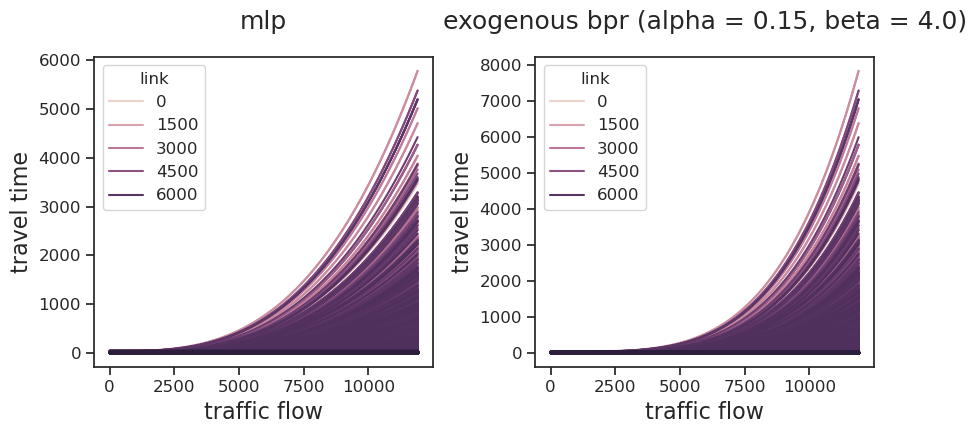

Index(['predicted_flow', 'predicted_traveltime', 'predicted_speed', 'hour',
       'sign', 'observed_traveltime', 'observed_flow', 'observed_speed'],
      dtype='object') (521640, 8) False
   predicted_flow  predicted_traveltime  predicted_speed  hour        sign  \
0        0.000000              7.461194        17.650528  12AM  consistent   
1       62.994202             12.167689        17.650528  12AM  consistent   
2       62.994202              7.461347        17.650166  12AM  consistent   
3        0.000000              7.364199        17.650526  12AM  consistent   
4        1.099963              6.497766        17.650528  12AM  consistent   

   observed_traveltime  observed_flow  observed_speed  
0                  NaN            NaN             NaN  
1                  NaN            NaN             NaN  
2                  NaN            NaN             NaN  
3                  NaN            NaN             NaN  
4                  NaN            NaN             NaN  


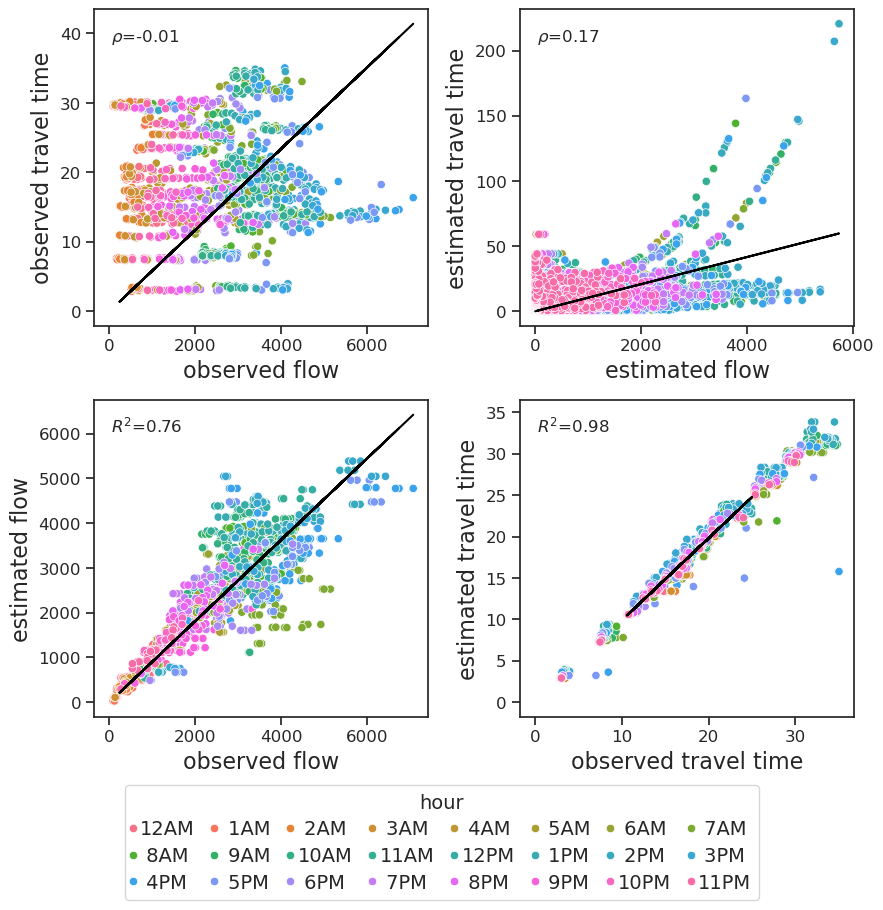

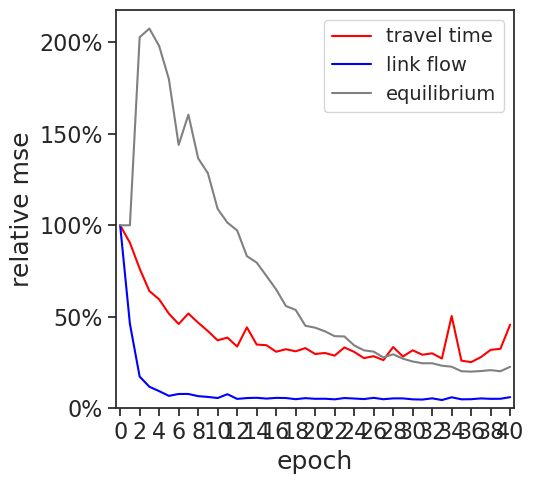

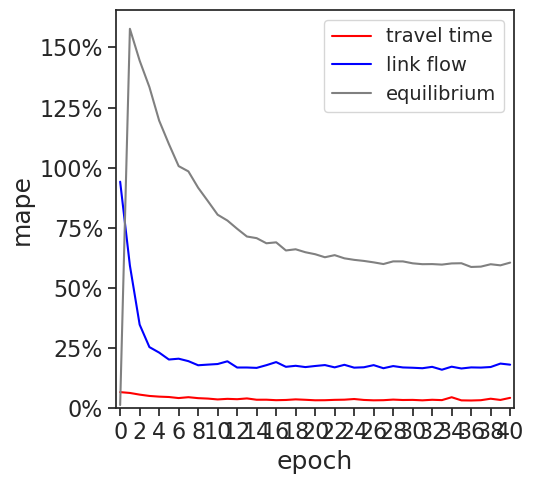

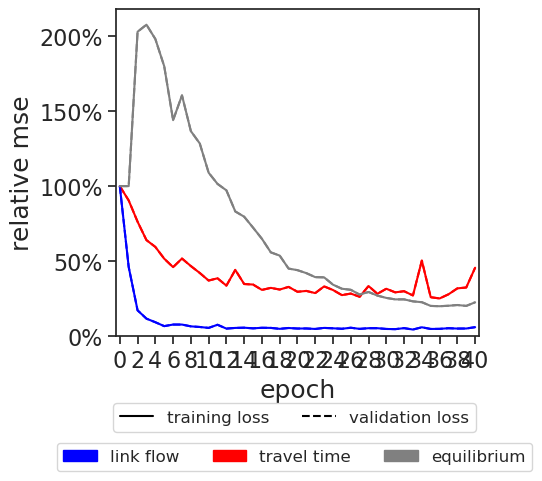

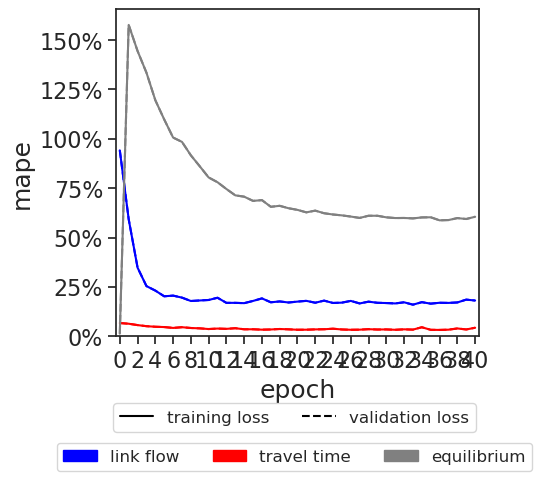

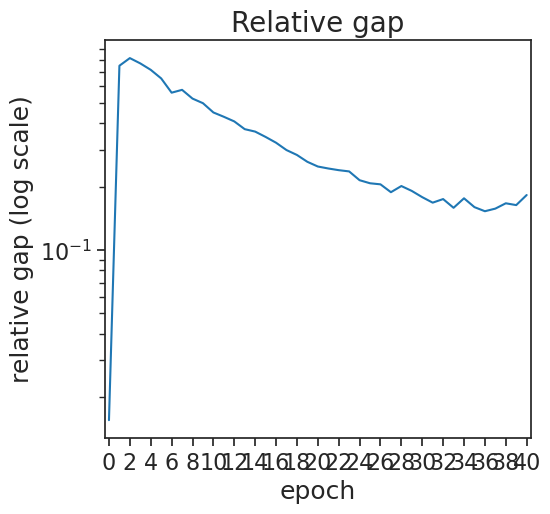

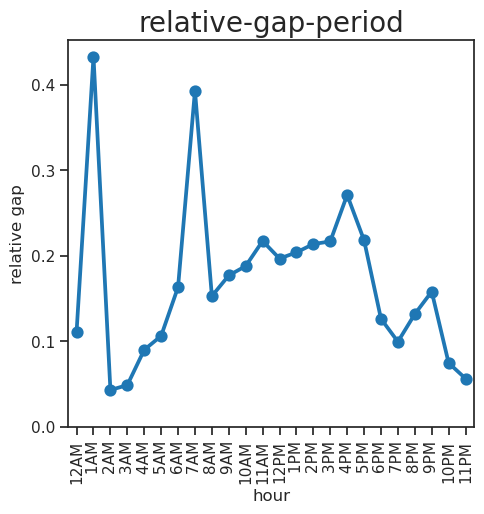

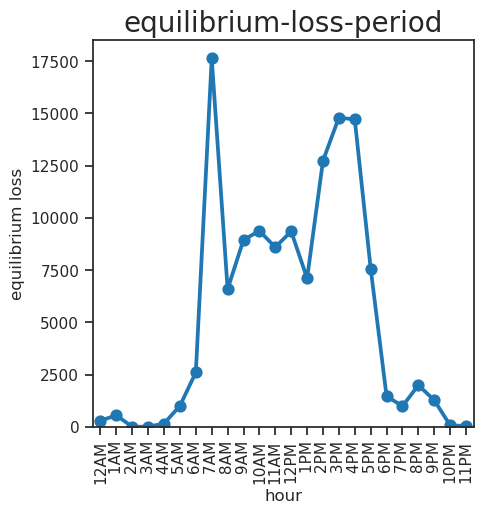

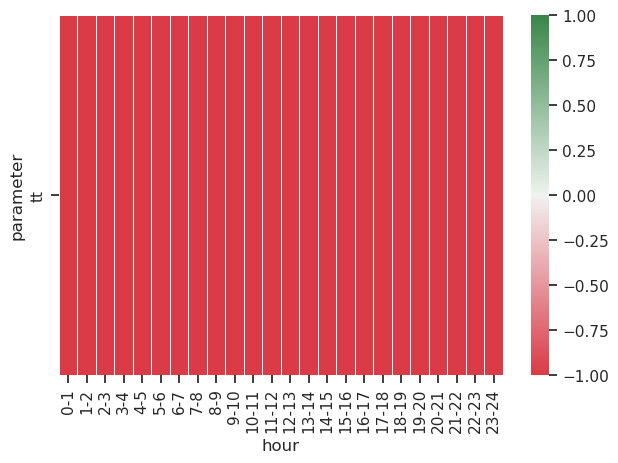

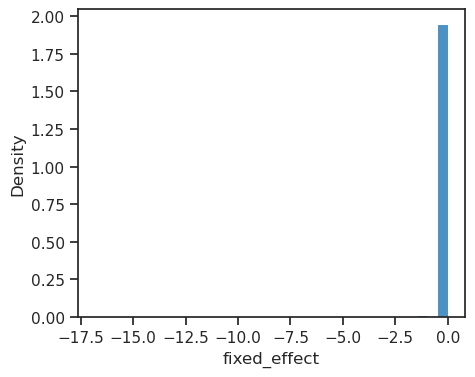

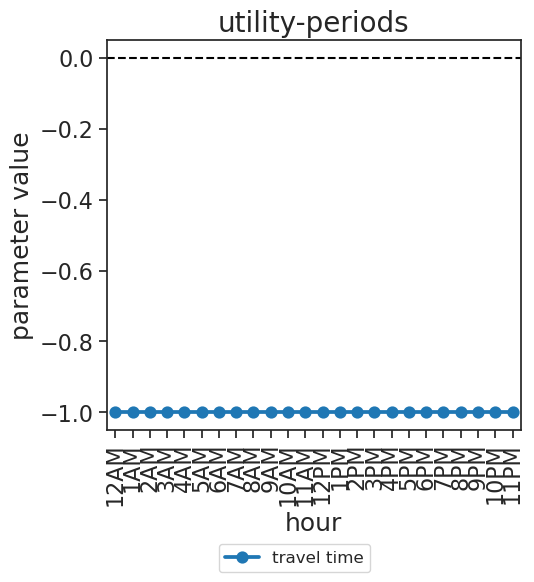

Theta: [[-1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1.]]


./src/mate/visualizations.py:786: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0.

  g = sns.pointplot(data=total_trips_by_hour, x=period_feature, y='total_trips', ax=ax,


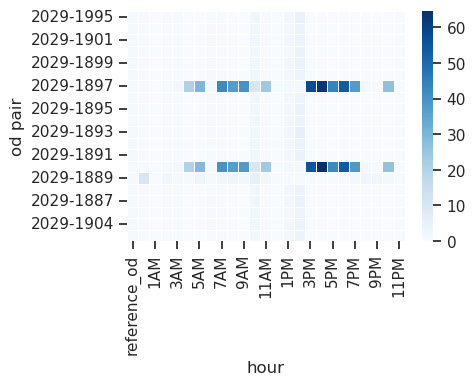

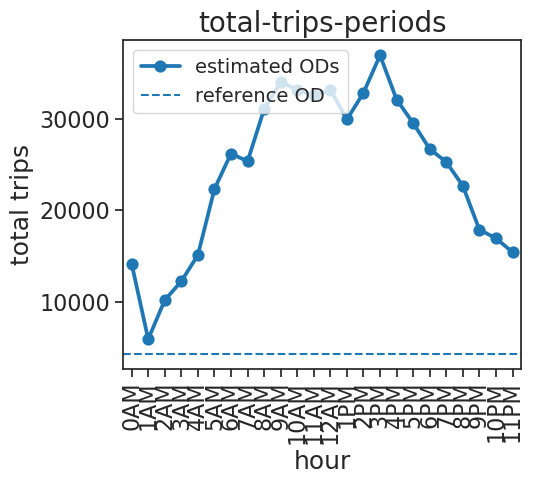

In [123]:
period_col= pd.DataFrame({"period": list(XT_train[:, :, -1].numpy().astype(int).flatten())})["period"].map(dict(zip(period_keys.period_id, period_keys.hour)))

# Model based metrics plotting
post_process_metrics.plot_performance_function(network, metrics_save_path, area_of_interest)

post_process_metrics.plot_flow_vs_traveltime(period_col, metrics_save_path, area_of_interest, 
                                plot_name=f"scatter-flow-traveltime-mate-{_YEAR}", 
                                hour_label=True, all_metrics=False)

post_process_metrics.plot_all_predictive_performance(train_results_dfs["MaTE"],
                            val_results_dfs["MaTE"],
                            _EVALUATION_METRIC,
                            metrics_save_path, 
                            area_of_interest)

post_process_metrics.plot_convergence_estimates(train_results_dfs["MaTE"],
                                                metrics_save_path, 
                                                area_of_interest)

post_process_metrics.plot_relative_gap_by_period(period_keys, metrics_save_path, area_of_interest)

post_process_metrics.plot_equilibrium_loss_by_period(period_keys, metrics_save_path, area_of_interest)

post_process_metrics.plot_rr_by_period(period_keys, metrics_save_path, area_of_interest)

post_process_metrics.plot_parameters_by_period(period_keys, metrics_save_path, area_of_interest)

reference_q=flat_od_from_generated_trips(reference_g, network.ods)
post_process_metrics.plot_top_od_flows_periods(period_keys, reference_q, metrics_save_path, area_of_interest)

# All Models report

./src/mate/visualizations.py:890: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0.

  g = sns.pointplot(data=total_trips_by_hour_models, x=period_feature, y='total_trips', ax=ax,


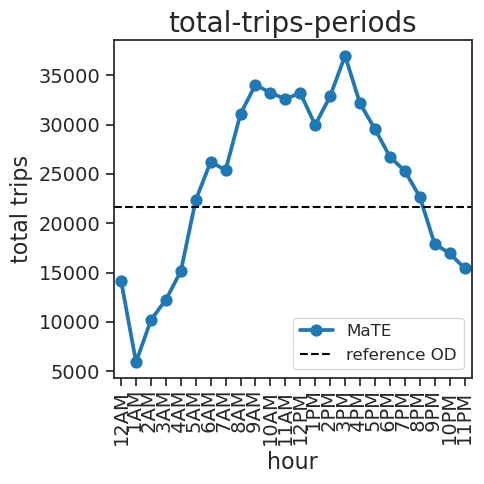

    hour   total_trips model  order
0   12AM  14168.080078  MaTE      0
1    1AM   5901.683105  MaTE      1
2    2AM  10183.696289  MaTE      2
3    3AM  12243.600586  MaTE      3
4    4AM  15123.050781  MaTE      4
5    5AM  22352.279297  MaTE      5
6    6AM  26240.136719  MaTE      6
7    7AM  25388.507812  MaTE      7
8    8AM  31104.691406  MaTE      8
9    9AM  34062.707031  MaTE      9
10  10AM  33237.511719  MaTE     10
11  11AM  32620.677734  MaTE     11
12  12PM  33214.285156  MaTE     12
13   1PM  29977.589844  MaTE     13
14   2PM  32889.902344  MaTE     14
15   3PM  37009.597656  MaTE     15
16   4PM  32158.060547  MaTE     16
17   5PM  29573.353516  MaTE     17
18   6PM  26749.513672  MaTE     18
19   7PM  25305.945312  MaTE     19
20   8PM  22703.853516  MaTE     20
21   9PM  17897.289062  MaTE     21
22  10PM  16954.535156  MaTE     22
23  11PM  15440.043945  MaTE     23
       total_trips
model             
MaTE    582500.625


In [124]:

from mattwin.postprocessing_metrics import plot_models_total_trips

# Metric plotting for all models:
#plot_models_convergence_plot(models, theta_df, train_results_dfs, metrics_save_path, area_of_interest)
#plot_models_rr_by_period(models, theta_df, period_keys, metrics_save_path, area_of_interest)
plot_models_total_trips(models, network, period_keys, metrics_save_path, area_of_interest)

## Write estimation results


In [125]:
train_results_df, val_results_df = map(
    lambda x: pd.concat(
        [results.assign(model=model)[["model"] + list(results.columns)] for model, results in x.items()],
        axis=0,
    ),
    [train_results_dfs, val_results_dfs],
)

#Check the folder exists 
if not os.path.exists(folder_path+"/output/tables"):
    os.makedirs(folder_path+"/output/tables")

train_filename = f"{ts}_train_results_{network.key}.csv"
val_filename = f"{ts}_validation_results_{network.key}.csv"
train_results_df.to_csv(folder_path+"/output/tables/"+f"{train_filename}")
print(f"File {train_filename} was written")
val_results_df.to_csv(folder_path+"/output/tables/"+f"{val_filename}")
print(f"File {val_filename} was written")

File 260213045856_train_results_Fresno.csv was written
File 260213045856_validation_results_Fresno.csv was written


## Summary of parameter estimates


### All models


In [126]:
models

{'MaTE': <mate.models.mate at 0x7f7651bcb940>}

In [127]:
results = pd.DataFrame({"parameter": [], "model": []})

for model_key, model in models.items():
    model_results = {
        **dict(zip(["tt"] + _FEATURES_Z, list(np.mean(model.theta.numpy(), axis=0)))),
        **{
            # "rr": float(model.get_parameters_estimates().eval("tt_sd/tt").iloc[0]),
            "tt": float(model.get_parameters_estimates().eval("tt").iloc[0]),
            "fixed_effect_mean": np.mean(model.fixed_effect),
            "fixed_effect_std": np.std(model.fixed_effect),
            "od_mean": np.mean(model.q),
            "od_std": np.std(model.q),
        },
    }

    if model.performance_function.type == "bpr":
        model_results = {
            **model_results,
            **{
                "alpha_mean": np.mean(model.performance_function.alpha),
                "alpha_std": np.std(model.performance_function.alpha),
                "beta_mean": np.mean(model.performance_function.beta),
                "beta_std": np.std(model.performance_function.beta),
            },
        }

    model_results = pd.DataFrame({"parameter": model_results.keys(), "values": model_results.values()}).assign(
        model=model_key
    )

    results = pd.concat([results, model_results])

In [128]:
print(results.pivot_table(index=["parameter"], columns="model", values="values", sort=False).round(4))

model                 MaTE
parameter                 
tt                 -1.0000
fixed_effect_mean  -0.1508
fixed_effect_std    0.9370
od_mean             1.1232
od_std             16.6250


### MaTE


In [129]:
# Stats by period
model = models["MaTE"]

with pd.option_context("display.float_format", "{:0.4f}".format):
    print("theta:", pd.DataFrame(model.theta.numpy().T))

theta:        0       1       2       3       4       5       6       7       8   \
0 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000   

       9       10      11      12      13      14      15      16      17  \
0 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000   

       18      19      20      21      22      23  
0 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000 -1.0000  


In [130]:
with pd.option_context("display.float_format", "{:0.4f}".format):
    if models["MaTE"].kappa is not None:
        print("kappa:", pd.DataFrame(model.kappa.numpy().T))

In [131]:
# with pd.option_context('display.float_format', '{:0.1f}'.format):
with pd.option_context("display.float_format", "{:0.4f}".format):
    print(
        "OD matrix",
        pd.DataFrame(
            {
                "od_mean": np.mean(model.q, axis=1),
                "od_std": np.std(model.q, axis=1),
                "od_total": np.sum(model.q, axis=1),
            }
        ).T,
    )

OD matrix                  0         1          2          3          4          5   \
od_mean      0.6557    0.2731     0.4713     0.5666     0.6999     1.0344   
od_std       8.1311    5.8578     4.8339     6.3421     9.1467    14.3507   
od_total 14168.1006 5901.6992 10183.6836 12243.6826 15123.0859 22352.5195   

                 6          7          8          9          10         11  \
od_mean      1.2143     1.1749     1.4394     1.5763     1.5381     1.5096   
od_std      18.3301    17.6435    21.2801    19.3914    18.4404    19.9947   
od_total 26239.8633 25388.2754 31105.0195 34063.0781 33237.3398 32620.5098   

                 12         13         14         15         16         17  \
od_mean      1.5371     1.3873     1.5220     1.7127     1.4882     1.3685   
od_std      22.7676    22.2646    22.7267    23.4920    24.1512    19.8130   
od_total 33214.6641 29977.5352 32889.6875 37009.6328 32157.5547 29572.7383   

                 18         19         20         21   

## Summary of models goodness of fit


In [132]:
results_losses = pd.DataFrame({})
loss_columns = ["loss_flow", "loss_traveltime", "loss_equilibrium", "loss_total"]

for model_key, model in models.items():
    results_losses_model = model.split_results(train_results_dfs[model_key])[1].assign(model=model_key)
    results_losses_model = results_losses_model[results_losses_model.epoch == _EPOCHS[model_key]["learning"]].iloc[[0]]
    results_losses = pd.concat([results_losses, results_losses_model])

results_losses[loss_columns] = (results_losses[loss_columns] - 1) * 100

In [133]:
with pd.option_context("display.float_format", "{:0.4f}".format):
    print(results_losses[["model"] + list(results_losses.columns)])

   model  epoch  loss_traveltime  loss_od  loss_theta  loss_flow  \
40  MaTE     40         -54.3347      NaN         NaN   -93.9314   

    loss_equilibrium  loss_bpr  loss_ntrips  loss_prop_od  \
40          -77.3610       NaN          NaN           NaN   

    loss_regularizer_kernel  loss_regularizer_utility_ods  \
40                      NaN                           NaN   

    loss_regularizer_od  loss_total  relative_gap model  
40                  NaN    -93.8459        0.1824  MaTE  


## Global runtime


In [134]:
print(f"runtime: {time.time()-t0_global:0.1f} [s]")

runtime: 61194.9 [s]
